In [1]:
from pathlib import Path
import time
import json
import joblib
import numpy as np
import pandas as pd
import torch

from sentence_transformers import SentenceTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

MODEL_NAME = "intfloat/multilingual-e5-small"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MAX_SEQ_LENGTH = 512
BATCH_SIZE = 32
RANDOM_STATE = 26

LABELS = ["Low", "Moderate", "High"]

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")

C:\Users\User\PycharmProjects\Peer_Review_Score_Prediction_from_Kazakh_and_English_Abstracts\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1110 19:01:33.589000 74860 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Device: cuda
GPU: NVIDIA GeForce RTX 4070 Ti SUPER


In [2]:
train_df = pd.read_parquet(ROOT / "data/splits/train.parquet")
val_df = pd.read_parquet(ROOT / "data/splits/validation.parquet")
test_df = pd.read_parquet(ROOT / "data/splits/test.parquet")

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (270, 11)
Validation: (57, 11)
Test: (58, 11)


In [3]:
def prepare_e5_text(df, language):
    title = df[f"title_{language}"].fillna("").astype(str)
    abstract = df[f"abstract_{language}"].fillna("").astype(str)

    text = (
        "query: "
        + "Title: "
        + title
        + " Abstract: "
        + abstract
    )

    result = df.copy()
    result["text"] = text

    return result


def expand_e5_multilingual(df):
    en = prepare_e5_text(df, "en")
    en["language"] = "English"

    kk = prepare_e5_text(df, "kk")
    kk["language"] = "Kazakh"

    return pd.concat([en, kk], ignore_index=True)


train_en = prepare_e5_text(train_df, "en")
val_en = prepare_e5_text(val_df, "en")
test_en = prepare_e5_text(test_df, "en")

train_kk = prepare_e5_text(train_df, "kk")
val_kk = prepare_e5_text(val_df, "kk")
test_kk = prepare_e5_text(test_df, "kk")

train_multi = expand_e5_multilingual(train_df)
val_multi = expand_e5_multilingual(val_df)
test_multi = expand_e5_multilingual(test_df)

In [4]:
e5_model = SentenceTransformer(
    MODEL_NAME,
    device=DEVICE
)

e5_model.max_seq_length = MAX_SEQ_LENGTH

print("Model loaded:", MODEL_NAME)
print("Device:", e5_model.device)
print("Embedding dimension:", e5_model.get_sentence_embedding_dimension())
print("Max sequence length:", e5_model.max_seq_length)

C:\Users\User\PycharmProjects\Peer_Review_Score_Prediction_from_Kazakh_and_English_Abstracts\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\User\.cache\huggingface\hub\models--intfloat--multilingual-e5-small. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\User\PycharmProjects\Peer_Revie

Model loaded: intfloat/multilingual-e5-small
Device: cuda:0
Embedding dimension: 384
Max sequence length: 512


C:\Users\User\AppData\Local\Temp\ipykernel_74860\3631813273.py:10: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Embedding dimension:", e5_model.get_sentence_embedding_dimension())


In [5]:
tokenizer = e5_model.tokenizer

def analyze_token_lengths(data, name):
    lengths = [
        len(tokenizer.encode(
            text,
            add_special_tokens=True,
            truncation=False
        ))
        for text in data["text"]
    ]

    lengths = np.array(lengths)

    print(f"\n{name}")
    print("Median:", np.median(lengths))
    print("95th percentile:", np.percentile(lengths, 95))
    print("Maximum:", lengths.max())
    print(
        "Truncated:",
        (lengths > MAX_SEQ_LENGTH).sum(),
        f"({(lengths > MAX_SEQ_LENGTH).mean() * 100:.2f}%)"
    )

    return lengths


lengths_en = analyze_token_lengths(train_en, "English")
lengths_kk = analyze_token_lengths(train_kk, "Kazakh")
lengths_multi = analyze_token_lengths(train_multi, "Multilingual")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (544 > 512). Running this sequence through the model will result in indexing errors



English
Median: 255.0
95th percentile: 419.0
Maximum: 556
Truncated: 4 (1.48%)

Kazakh
Median: 288.0
95th percentile: 471.0
Maximum: 615
Truncated: 4 (1.48%)

Multilingual
Median: 272.0
95th percentile: 434.14999999999986
Maximum: 615
Truncated: 8 (1.48%)


In [6]:
embedding_dir = ROOT / "models" / "transformer" / "embeddings"
embedding_dir.mkdir(parents=True, exist_ok=True)


def generate_embeddings(data, name):
    start = time.perf_counter()

    embeddings = e5_model.encode(
        data["text"].tolist(),
        batch_size=BATCH_SIZE,
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=True
    )

    elapsed = time.perf_counter() - start

    np.save(
        embedding_dir / f"{name}.npy",
        embeddings
    )

    print(f"\n{name}")
    print("Shape:", embeddings.shape)
    print("Time:", round(elapsed, 3), "seconds")

    return embeddings


X_train_en = generate_embeddings(train_en, "train_en")
X_val_en = generate_embeddings(val_en, "validation_en")
X_test_en = generate_embeddings(test_en, "test_en")

X_train_kk = generate_embeddings(train_kk, "train_kk")
X_val_kk = generate_embeddings(val_kk, "validation_kk")
X_test_kk = generate_embeddings(test_kk, "test_kk")

X_train_multi = generate_embeddings(train_multi, "train_multi")
X_val_multi = generate_embeddings(val_multi, "validation_multi")
X_test_multi = generate_embeddings(test_multi, "test_multi")

Batches: 100%|██████████| 9/9 [00:00<00:00, 11.38it/s]



train_en
Shape: (270, 384)
Time: 0.794 seconds


Batches: 100%|██████████| 2/2 [00:00<00:00, 16.74it/s]



validation_en
Shape: (57, 384)
Time: 0.122 seconds


Batches: 100%|██████████| 2/2 [00:00<00:00, 17.78it/s]



test_en
Shape: (58, 384)
Time: 0.116 seconds


... (8 outputs left out)

Batches: 100%|██████████| 4/4 [00:00<00:00, 21.05it/s]



validation_multi
Shape: (114, 384)
Time: 0.193 seconds


Batches: 100%|██████████| 4/4 [00:00<00:00, 22.34it/s]


test_multi
Shape: (116, 384)
Time: 0.182 seconds


In [7]:
def train_e5_classifier(X_train, y_train, X_val, y_val):
    best_model = None
    best_score = -1
    best_params = None

    for C in [0.1, 1.0, 10.0]:
        for class_weight in [None, "balanced"]:

            classifier = LogisticRegression(
                C=C,
                class_weight=class_weight,
                max_iter=3000,
                random_state=RANDOM_STATE
            )

            classifier.fit(X_train, y_train)

            predictions = classifier.predict(X_val)

            score = f1_score(
                y_val,
                predictions,
                average="macro",
                zero_division=0
            )

            print(
                f"C={C}, class_weight={class_weight}, "
                f"Validation Macro F1={score:.4f}"
            )

            if score > best_score:
                best_score = score
                best_model = classifier
                best_params = {
                    "C": C,
                    "class_weight": class_weight
                }

    return best_model, best_params, best_score

In [8]:

# Prepare labels
y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

experiments = {
    "english": (X_train_en, X_val_en, X_test_en),
    "kazakh": (X_train_kk, X_val_kk, X_test_kk),
    "multilingual": (X_train_multi, X_val_multi, X_test_multi)
}

models_dir = ROOT / "models" / "transformer"
models_dir.mkdir(parents=True, exist_ok=True)

results = []
trained_models = {}

for name, (X_tr, X_v, X_te) in experiments.items():

    print(f"\n{'='*50}")
    print(f"EXPERIMENT: {name.upper()}")
    print(f"{'='*50}")

    # Duplicate labels for multilingual representations
    if name == "multilingual":
        y_tr = np.concatenate([y_train, y_train])
        y_v = np.concatenate([y_val, y_val])
        y_te = np.concatenate([y_test, y_test])
    else:
        y_tr, y_v, y_te = y_train, y_val, y_test

    # Hyperparameter selection on validation
    best_model, best_params, best_val_f1 = train_e5_classifier(
        X_tr, y_tr, X_v, y_v
    )

    # Refit on Train + Validation
    X_train_full = np.concatenate([X_tr, X_v])
    y_train_full = np.concatenate([y_tr, y_v])

    final_model = LogisticRegression(
        C=best_params["C"],
        class_weight=best_params["class_weight"],
        max_iter=3000,
        random_state=RANDOM_STATE
    )

    final_model.fit(X_train_full, y_train_full)

    # Final test evaluation
    predictions = final_model.predict(X_te)

    accuracy = accuracy_score(y_te, predictions)
    precision = precision_score(
        y_te, predictions, average="macro", zero_division=0
    )
    recall = recall_score(
        y_te, predictions, average="macro", zero_division=0
    )
    macro_f1 = f1_score(
        y_te, predictions, average="macro", zero_division=0
    )
    weighted_f1 = f1_score(
        y_te, predictions, average="weighted", zero_division=0
    )

    print("\nBest parameters:", best_params)
    print("Validation Macro F1:", round(best_val_f1, 4))
    print("Test Accuracy:", round(accuracy, 4))
    print("Test Macro F1:", round(macro_f1, 4))
    print("\nClassification report:")
    print(classification_report(
        y_te,
        predictions,
        labels=LABELS,
        zero_division=0
    ))

    # Save model
    model_path = models_dir / f"e5_{name}.joblib"
    joblib.dump(final_model, model_path)

    trained_models[name] = final_model

    results.append({
        "model": f"e5_{name}",
        "best_C": best_params["C"],
        "class_weight": str(best_params["class_weight"]),
        "validation_macro_f1": best_val_f1,
        "test_accuracy": accuracy,
        "test_precision_macro": precision,
        "test_recall_macro": recall,
        "test_macro_f1": macro_f1,
        "test_weighted_f1": weighted_f1
    })

transformer_results = pd.DataFrame(results)

results_dir = ROOT / "results"
results_dir.mkdir(parents=True, exist_ok=True)

transformer_results.to_csv(
    results_dir / "transformer_metrics.csv",
    index=False
)

print("\nFINAL TRANSFORMER RESULTS")
display(
    transformer_results.sort_values(
        "validation_macro_f1",
        ascending=False
    )
)



EXPERIMENT: ENGLISH
C=0.1, class_weight=None, Validation Macro F1=0.2536
C=0.1, class_weight=balanced, Validation Macro F1=0.4720
C=1.0, class_weight=None, Validation Macro F1=0.2536
C=1.0, class_weight=balanced, Validation Macro F1=0.4519
C=10.0, class_weight=None, Validation Macro F1=0.2536
C=10.0, class_weight=balanced, Validation Macro F1=0.3955

Best parameters: {'C': 0.1, 'class_weight': 'balanced'}
Validation Macro F1: 0.472
Test Accuracy: 0.3793
Test Macro F1: 0.3169

Classification report:
              precision    recall  f1-score   support

         Low       0.06      0.14      0.09         7
    Moderate       0.60      0.43      0.50        35
        High       0.35      0.38      0.36        16

    accuracy                           0.38        58
   macro avg       0.34      0.32      0.32        58
weighted avg       0.47      0.38      0.41        58


EXPERIMENT: KAZAKH
C=0.1, class_weight=None, Validation Macro F1=0.2536
C=0.1, class_weight=balanced, Validation 

,model,best_C,class_weight,validation_macro_f1,test_accuracy,test_precision_macro,test_recall_macro,test_macro_f1,test_weighted_f1
0,e5_english,0.1,balanced,0.472035,0.379310,0.338480,0.315476,0.316864,0.412532
2,e5_multilingual,10.0,balanced,0.470786,0.491379,0.356980,0.335714,0.339614,0.483850
1,e5_kazakh,1.0,balanced,0.344571,0.396552,0.328242,0.317857,0.298308,0.408798


In [9]:

from sklearn.metrics import classification_report, accuracy_score, f1_score

multilingual_model = trained_models["multilingual"]

# First 58 rows are English, next 58 are Kazakh
n_test = len(test_df)

predictions_multi = multilingual_model.predict(X_test_multi)

language_results = []

for language, start, end in [
    ("English", 0, n_test),
    ("Kazakh", n_test, 2 * n_test)
]:
    y_true_lang = y_test
    y_pred_lang = predictions_multi[start:end]

    print(f"\n{'='*45}")
    print(f"{language.upper()} — MULTILINGUAL E5")
    print(f"{'='*45}")

    print(classification_report(
        y_true_lang,
        y_pred_lang,
        labels=LABELS,
        zero_division=0
    ))

    language_results.append({
        "language": language,
        "accuracy": accuracy_score(y_true_lang, y_pred_lang),
        "macro_f1": f1_score(
            y_true_lang,
            y_pred_lang,
            labels=LABELS,
            average="macro",
            zero_division=0
        ),
        "weighted_f1": f1_score(
            y_true_lang,
            y_pred_lang,
            average="weighted",
            zero_division=0
        )
    })

language_results_df = pd.DataFrame(language_results)
display(language_results_df)



ENGLISH — MULTILINGUAL E5
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00         7
    Moderate       0.63      0.74      0.68        35
        High       0.36      0.25      0.30        16

    accuracy                           0.52        58
   macro avg       0.33      0.33      0.33        58
weighted avg       0.48      0.52      0.49        58


KAZAKH — MULTILINGUAL E5
              precision    recall  f1-score   support

         Low       0.08      0.14      0.11         7
    Moderate       0.59      0.63      0.61        35
        High       0.44      0.25      0.32        16

    accuracy                           0.47        58
   macro avg       0.37      0.34      0.35        58
weighted avg       0.49      0.47      0.47        58



,language,accuracy,macro_f1,weighted_f1
0,English,0.517241,0.326836,0.494623
1,Kazakh,0.465517,0.345458,0.469754


In [10]:
# TRANSFORMER BENCHMARK: E5
import statistics
from huggingface_hub import snapshot_download

# 1. Load the encoder separately for benchmarking
benchmark_encoder = SentenceTransformer(
    MODEL_NAME,
    device=DEVICE
)
benchmark_encoder.max_seq_length = MAX_SEQ_LENGTH

# GPU synchronization for accurate timing
def sync_device():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

# 2. Count model parameters
total_parameters = sum(
    parameter.numel()
    for parameter in benchmark_encoder.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in benchmark_encoder.parameters()
    if parameter.requires_grad
)

# 3. Calculate model size on disk
snapshot_path = Path(snapshot_download(repo_id=MODEL_NAME))

unique_files = set()
model_size_bytes = 0

for file_path in snapshot_path.rglob("*"):
    if file_path.is_file():
        resolved_path = file_path.resolve()

        if resolved_path not in unique_files:
            unique_files.add(resolved_path)
            model_size_bytes += resolved_path.stat().st_size

model_size_mb = model_size_bytes / (1024 ** 2)

print("MODEL INFORMATION")
print(f"Model: {MODEL_NAME}")
print(f"Device: {DEVICE}")
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")
print(f"Model size: {model_size_mb:.2f} MB")

# 4. Prepare raw test texts
def make_benchmark_texts(df, language):
    if language == "english":
        title_col = "title_en"
        abstract_col = "abstract_en"
    elif language == "kazakh":
        title_col = "title_kk"
        abstract_col = "abstract_kk"
    else:
        raise ValueError("Unsupported language")

    texts = []

    for _, row in df.iterrows():
        title = str(row[title_col])
        abstract = str(row[abstract_col])

        text = f"query: Title: {title} Abstract: {abstract}"
        texts.append(text)

    return texts

texts_en = make_benchmark_texts(test_df, "english")
texts_kk = make_benchmark_texts(test_df, "kazakh")

# 1000 multilingual texts: 500 English + 500 Kazakh
texts_multi = (texts_en + texts_kk) * 9
texts_multi = texts_multi[:1000]

# Repeat test texts to get exactly 1000 examples
def repeat_to_1000(texts):
    return (texts * (1000 // len(texts) + 1))[:1000]

benchmark_text_sets = {
    "english": repeat_to_1000(texts_en),
    "kazakh": repeat_to_1000(texts_kk),
    "multilingual": texts_multi
}

# 5. Benchmark embedding generation
def benchmark_encoding(texts, repeats=3):
    # Warm-up
    benchmark_encoder.encode(
        texts[:min(32, len(texts))],
        batch_size=BATCH_SIZE,
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=False
    )
    sync_device()

    timings = []

    for _ in range(repeats):
        sync_device()
        start = time.perf_counter()

        embeddings = benchmark_encoder.encode(
            texts,
            batch_size=BATCH_SIZE,
            convert_to_numpy=True,
            normalize_embeddings=True,
            show_progress_bar=False
        )

        sync_device()
        elapsed = time.perf_counter() - start
        timings.append(elapsed)

    return statistics.median(timings), embeddings

# 6. Benchmark classifier prediction
def benchmark_classifier(classifier, embeddings, repeats=5):
    # Warm-up
    classifier.predict(embeddings[:32])

    timings = []

    for _ in range(repeats):
        start = time.perf_counter()
        classifier.predict(embeddings)
        elapsed = time.perf_counter() - start
        timings.append(elapsed)

    return statistics.median(timings)

# 7. Run all experiments
benchmark_rows = []

for name, texts in benchmark_text_sets.items():

    print(f"\nBenchmarking E5 {name.upper()}...")

    embedding_time, embeddings = benchmark_encoding(texts)

    classifier = trained_models[name]
    classifier_time = benchmark_classifier(
        classifier,
        embeddings
    )

    total_time = embedding_time + classifier_time

    benchmark_rows.append({
        "model": f"e5_{name}",
        "model_parameters": total_parameters,
        "model_size_mb": model_size_mb,
        "embedding_time_1000_sec": embedding_time,
        "classifier_time_1000_sec": classifier_time,
        "total_inference_time_1000_sec": total_time,
        "total_inference_time_1000_ms": total_time * 1000,
        "device": DEVICE
    })

    print(f"Embedding time: {embedding_time:.4f} sec")
    print(f"Classifier time: {classifier_time:.4f} sec")
    print(f"Total time: {total_time:.4f} sec")

# 8. Save results
transformer_benchmark_df = pd.DataFrame(benchmark_rows)

results_dir = ROOT / "results"
results_dir.mkdir(parents=True, exist_ok=True)

transformer_benchmark_df.to_csv(
    results_dir / "transformer_benchmark.csv",
    index=False
)

print("\nTRANSFORMER BENCHMARK RESULTS")
display(transformer_benchmark_df)


Fetching 43 files: 100%|██████████| 43/43 [00:25<00:00,  1.66it/s]


MODEL INFORMATION
Model: intfloat/multilingual-e5-small
Device: cuda
Total parameters: 117,653,760
Trainable parameters: 117,653,760
Model size: 2174.57 MB

Benchmarking E5 ENGLISH...
Embedding time: 1.1595 sec
Classifier time: 0.0004 sec
Total time: 1.1599 sec

Benchmarking E5 KAZAKH...
Embedding time: 1.2697 sec
Classifier time: 0.0003 sec
Total time: 1.2700 sec

Benchmarking E5 MULTILINGUAL...
Embedding time: 1.2437 sec
Classifier time: 0.0003 sec
Total time: 1.2440 sec

TRANSFORMER BENCHMARK RESULTS


,model,model_parameters,model_size_mb,embedding_time_1000_sec,classifier_time_1000_sec,total_inference_time_1000_sec,total_inference_time_1000_ms,device
0,e5_english,117653760,2174.570049,1.159497,0.000400,1.159897,1159.8970,cuda
1,e5_kazakh,117653760,2174.570049,1.269710,0.000306,1.270016,1270.0159,cuda
2,e5_multilingual,117653760,2174.570049,1.243739,0.000265,1.244004,1244.0041,cuda


In [11]:
# ACTUAL E5 MODEL WEIGHTS SIZE

# Size of tensors actually loaded into the model
state_dict = benchmark_encoder.state_dict()

weights_bytes = sum(
    tensor.numel() * tensor.element_size()
    for tensor in state_dict.values()
)

weights_mb = weights_bytes / (1024 ** 2)

# Also inspect the classifier sizes
classifier_sizes = {}

for name, model in trained_models.items():
    model_path = models_dir / f"e5_{name}.joblib"
    classifier_sizes[name] = model_path.stat().st_size / (1024 ** 2)

print("E5 MODEL SIZE ANALYSIS")
print(f"Repository snapshot size: {model_size_mb:.2f} MB")
print(f"Loaded model weights: {weights_mb:.2f} MB")
print(f"Total parameters: {total_parameters:,}")
print(f"Weight dtype: {next(benchmark_encoder.parameters()).dtype}")

print("\nCLASSIFIER SIZES")
for name, size in classifier_sizes.items():
    print(f"{name}: {size:.4f} MB")

# Save corrected model size information
size_report = pd.DataFrame([{
    "model": MODEL_NAME,
    "parameters": total_parameters,
    "loaded_weights_mb": weights_mb,
    "repository_snapshot_mb": model_size_mb,
    "weight_dtype": str(next(benchmark_encoder.parameters()).dtype)
}])

size_report.to_csv(
    results_dir / "transformer_model_size.csv",
    index=False
)

display(size_report)


E5 MODEL SIZE ANALYSIS
Repository snapshot size: 2174.57 MB
Loaded model weights: 448.81 MB
Total parameters: 117,653,760
Weight dtype: torch.float32

CLASSIFIER SIZES
english: 0.0054 MB
kazakh: 0.0054 MB
multilingual: 0.0054 MB


,model,parameters,loaded_weights_mb,repository_snapshot_mb,weight_dtype
0,intfloat/multilingual-e5-small,117653760,448.813477,2174.570049,torch.float32


### Transformer Model Size and Computational Efficiency

The pretrained `intfloat/multilingual-e5-small` model contains 117,653,760 parameters. The loaded model weights occupy 448.81 MB in FP32 format. The repository snapshot occupies approximately 2,174.57 MB, but this value includes additional repository files and is not used as the primary model-size measurement.

The Transformer encoder performs the computationally intensive part of inference by generating text embeddings. The Logistic Regression classifier adds negligible overhead.

The total inference time for 1,000 texts ranged from 1.16 to 1.27 seconds on an NVIDIA GeForce RTX 4070 Ti SUPER GPU. The classifier itself required less than 0.001 seconds for 1,000 embeddings.

The results demonstrate that most of the computational cost comes from Transformer-based embedding generation rather than the classification layer.

E5 ENGLISH — CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Low       0.06      0.14      0.09         7
    Moderate       0.60      0.43      0.50        35
        High       0.35      0.38      0.36        16

    accuracy                           0.38        58
   macro avg       0.34      0.32      0.32        58
weighted avg       0.47      0.38      0.41        58



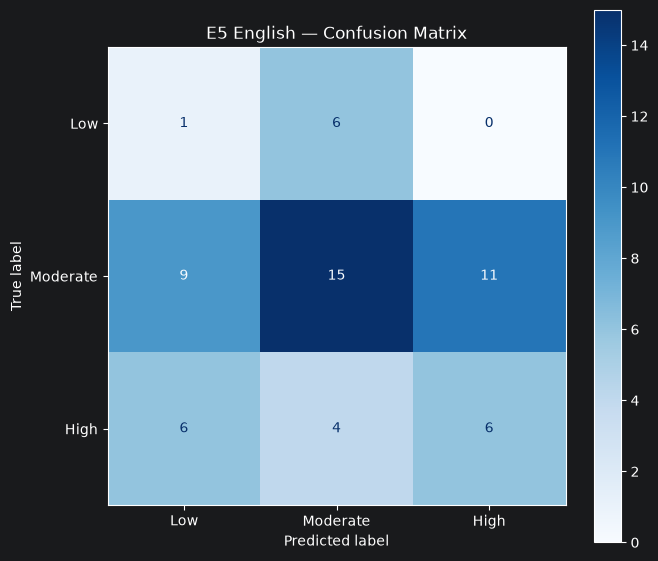


ERROR ANALYSIS SUMMARY
Total test samples: 58
Correct predictions: 22
Incorrect predictions: 36
Error rate: 0.6207

ERROR TYPES


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [12]:
# E5 ENGLISH - ERROR ANALYSIS
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# 1. Predict test data
e5_model = trained_models["english"]
e5_predictions = e5_model.predict(X_test_en)

y_true = test_df["label"].to_numpy()

# 2. Classification report
print("E5 ENGLISH — CLASSIFICATION REPORT")
print(classification_report(
    y_true,
    e5_predictions,
    labels=LABELS,
    zero_division=0
))

# 3. Confusion matrix
cm = confusion_matrix(
    y_true,
    e5_predictions,
    labels=LABELS
)

fig, ax = plt.subplots(figsize=(7, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=LABELS
)

display.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("E5 English — Confusion Matrix")
plt.tight_layout()

error_dir = ROOT / "results" / "error_analysis"
error_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    error_dir / "e5_english_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 4. Build predictions dataframe
e5_error_df = test_df.copy()

e5_error_df["true_label"] = y_true
e5_error_df["predicted_label"] = e5_predictions
e5_error_df["is_correct"] = (
    e5_error_df["true_label"] ==
    e5_error_df["predicted_label"]
)

# 5. Extract incorrect predictions
e5_errors = e5_error_df[
    ~e5_error_df["is_correct"]
].copy()

e5_errors["error_type"] = (
    e5_errors["true_label"].astype(str)
    + " -> "
    + e5_errors["predicted_label"].astype(str)
)

# 6. Save results
e5_error_df.to_csv(
    error_dir / "e5_english_all_predictions.csv",
    index=False
)

e5_errors.to_csv(
    error_dir / "e5_english_errors.csv",
    index=False
)

e5_error_df.to_parquet(
    error_dir / "e5_english_all_predictions.parquet",
    index=False
)

e5_errors.to_parquet(
    error_dir / "e5_english_errors.parquet",
    index=False
)

# 7. Summary
print("\nERROR ANALYSIS SUMMARY")
print("Total test samples:", len(e5_error_df))
print("Correct predictions:", e5_error_df["is_correct"].sum())
print("Incorrect predictions:", len(e5_errors))
print(
    "Error rate:",
    round(len(e5_errors) / len(e5_error_df), 4)
)

print("\nERROR TYPES")
display(
    e5_errors["error_type"]
    .value_counts()
    .rename_axis("error_type")
    .reset_index(name="count")
)

# 8. Show examples of errors
display(
    e5_errors[
        [
            "paper_id",
            "true_label",
            "predicted_label",
            "error_type",
            "title_en",
            "abstract_en"
        ]
    ].head(10)
)


In [13]:

from IPython.display import display as show_table

# Error types
print("ERROR TYPES")

error_types_df = (
    e5_errors["error_type"]
    .value_counts()
    .rename_axis("error_type")
    .reset_index(name="count")
)

show_table(error_types_df)

# Show incorrect predictions
print("\nINCORRECT PREDICTION EXAMPLES")

show_table(
    e5_errors[
        [
            "paper_id",
            "true_label",
            "predicted_label",
            "error_type",
            "title_en",
            "abstract_en"
        ]
    ].head(10)
)

# Save error types
error_types_df.to_csv(
    error_dir / "e5_english_error_types.csv",
    index=False
)


ERROR TYPES


,error_type,count
0,Moderate -> High,11
1,Moderate -> Low,9
2,High -> Low,6
3,Low -> Moderate,6
4,High -> Moderate,4



INCORRECT PREDICTION EXAMPLES


,paper_id,true_label,predicted_label,error_type,title_en,abstract_en
0,p_3a8b852aecdf584a,Moderate,High,Moderate -> High,Projects of Digital Transformation of Shipbuil...,The problem of digital transformation of Ukrai...
2,p_4d353ea399ce1a15,Moderate,High,Moderate -> High,"Ethnocultural, Educational and Scientific Pote...",The article analyzes the features of an intera...
3,p_4d353ea399ce1a15,Moderate,High,Moderate -> High,"Ethnocultural, Educational and Scientific Pote...",The article analyzes the features of an intera...
4,p_f0b9a6b2cdfe8f53,Moderate,Low,Moderate -> Low,Using Video Games as a Tool in Math Education,"Today, you can see how children are increasing..."
5,p_f0b9a6b2cdfe8f53,High,Low,High -> Low,Using Video Games as a Tool in Math Education,"Today, you can see how children are increasing..."
7,p_2965cbbbca196b21,Moderate,Low,Moderate -> Low,Composite Citizens in the Smart City: Rethinki...,Theimplementation of smart cities has undergon...
8,p_9db0c6080c6bd53a,Moderate,Low,Moderate -> Low,Topic Modeling for Recent Newspaper Publicatio...,This paper aims to investigate the recent disc...
9,p_9db0c6080c6bd53a,High,Low,High -> Low,Topic Modeling for Recent Newspaper Publicatio...,This paper aims to investigate the recent disc...
10,p_666cdd8af53f1384,Moderate,High,Moderate -> High,Formalized Management of Changes at the Enterp...,The article presents a significantly updated a...
11,p_666cdd8af53f1384,Moderate,High,Moderate -> High,Formalized Management of Changes at the Enterp...,The article presents a significantly updated a...


### Error Analysis — E5 English

The E5 English classifier correctly predicted 22 out of 58 test samples, resulting in an accuracy of 37.93% and a macro F1-score of 0.3169.

The Moderate class achieved the highest F1-score of 0.50, followed by High with 0.36. The Low class showed the weakest performance, with an F1-score of 0.09.

These results indicate that the model has difficulty distinguishing minority-class examples, particularly Low scores. The small number of Low observations in the test set (7 samples) also makes class-specific performance estimates less stable.

Overall, the pretrained multilingual-e5-small embeddings combined with Logistic Regression did not demonstrate a clear improvement over the TF-IDF baseline on this dataset.

In [25]:
print("|" + ("=|"*32))
print("Summary " * 8)
print("|" + ("=|"*32))

|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|
Summary Summary Summary Summary Summary Summary Summary Summary 
|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|=|


### Comparative Error Analysis: TF-IDF vs Transformer

The error analysis showed that E5 English produced 36 incorrect predictions out of 58 test samples, corresponding to an error rate of 62.07%. Its most frequent error was classifying Moderate reviews as High (11 cases), followed by Moderate as Low (9 cases).

Compared with the TF-IDF English Char baseline, which produced 32 errors, E5 English demonstrated slightly weaker performance. TF-IDF achieved a test Macro F1-score of 0.3316, while E5 achieved 0.3169.

The models also demonstrated different error patterns. E5 more frequently confused Moderate and High with Low, whereas TF-IDF more frequently confused High with Moderate. Both models struggled with the minority Low class.

An additional dataset limitation is that multiple reviewers may assign different scores to the same paper. Since the models use paper titles and abstracts as input, they cannot observe reviewer-specific preferences or evaluation criteria. This introduces ambiguity into the prediction task.

Overall, the TF-IDF character n-gram baseline outperformed the E5 English model on the test set, despite E5 achieving a higher validation Macro F1-score.